# UTS Pemodelan dan Simulasi (MOSI) — Sistem Dinamik Neraca Ketersediaan dan Kebutuhan Air Bersih Kota Bandung

**Identitas Mahasiswa:**
* **Nama:** Sigit Miraj Permana
* **NIM:** 301240037
* **Kelas / Semester:** 5B / Semester 5
* **Program Studi:** Teknik Informatika — Fakultas Teknologi Informasi, Universitas Bale Bandung (FTI UNIBBA)

---

### Deskripsi Studi Kasus & Sumber Dataset Terbuka
Notebook ini mengimplementasikan pemodelan dan simulasi **Sistem Dinamik (*System Dynamics Modelling*)** menggunakan integrasi numerik **Euler ($\Delta t = 0,25$ tahun)** untuk mengevaluasi neraca ketersediaan dan kebutuhan air bersih di Kota Bandung pada periode **2016–2035**.

**Dataset Empiris (Open Data Kota Bandung):**
1. **Jumlah Air Minum yang Disalurkan oleh PDAM Tirtawening Kota Bandung (2016–2021)** — 72 observasi bulanan dalam satuan meter kubik ($\text{m}^3$).
2. **Jumlah Penduduk Kota Bandung (2017–2025)** — Dinas Kependudukan dan Pencatatan Sipil Kota Bandung dalam satuan jiwa.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches

plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cbd5e1'
plt.rcParams['axes.linewidth'] = 0.8

df_air = pd.read_csv('data/pdam_tirtawening_bandung.csv')
df_pop = pd.read_csv('data/penduduk_kota_bandung.csv').sort_values('tahun').reset_index(drop=True)

bulan_map = {
    'JANUARI': 1, 'FEBRUARI': 2, 'MARET': 3, 'APRIL': 4,
    'MEI': 5, 'JUNI': 6, 'JULI': 7, 'AGUSTUS': 8,
    'SEPTEMBER': 9, 'OKTOBER': 10, 'NOVEMBER': 11, 'DESEMBER': 12
}
df_air['bulan_num'] = df_air['bulan'].map(bulan_map)
df_air = df_air.sort_values(['tahun', 'bulan_num']).reset_index(drop=True)
air_yearly = df_air.groupby('tahun')['jumlah_air_minum_disalurkan'].sum().reset_index()

print("=== RINGKASAN DATA PASOKAN AIR PDAM TIRTAWENING (2016–2021) ===")
print(air_yearly.to_string(index=False))
print("\n=== RINGKASAN DATA PENDUDUK KOTA BANDUNG (2017–2025) ===")
print(df_pop[['tahun', 'jumlah_penduduk', 'satuan']].to_string(index=False))


=== RINGKASAN DATA PASOKAN AIR PDAM TIRTAWENING (2016–2021) ===
 tahun  jumlah_air_minum_disalurkan
  2016                     42528447
  2017                     42000663
  2018                     41859962
  2019                     39349569
  2020                     37929761
  2021                     37847379

=== RINGKASAN DATA PENDUDUK KOTA BANDUNG (2017–2025) ===
 tahun  jumlah_penduduk satuan
  2017          2412458  ORANG
  2018          2452179  ORANG
  2019          2480464  ORANG
  2020          2500965  ORANG
  2021          2527854  ORANG
  2022          2545005  ORANG
  2023          2569107  ORANG
  2024          2591763  ORANG
  2025          2605916  ORANG


### 1. Exploratory Data Analysis (EDA) & Kesenjangan (*Gap*) Historis
Tahap ini mengeksplorasi fluktuasi bulanan distribusi air PDAM Tirtawening (2016–2021) serta membandingkannya terhadap standar kebutuhan air bersih perkotaan Kota Metropolitan ($150\text{ liter/orang/hari}$ sesuai SNI / Ditjen Cipta Karya).


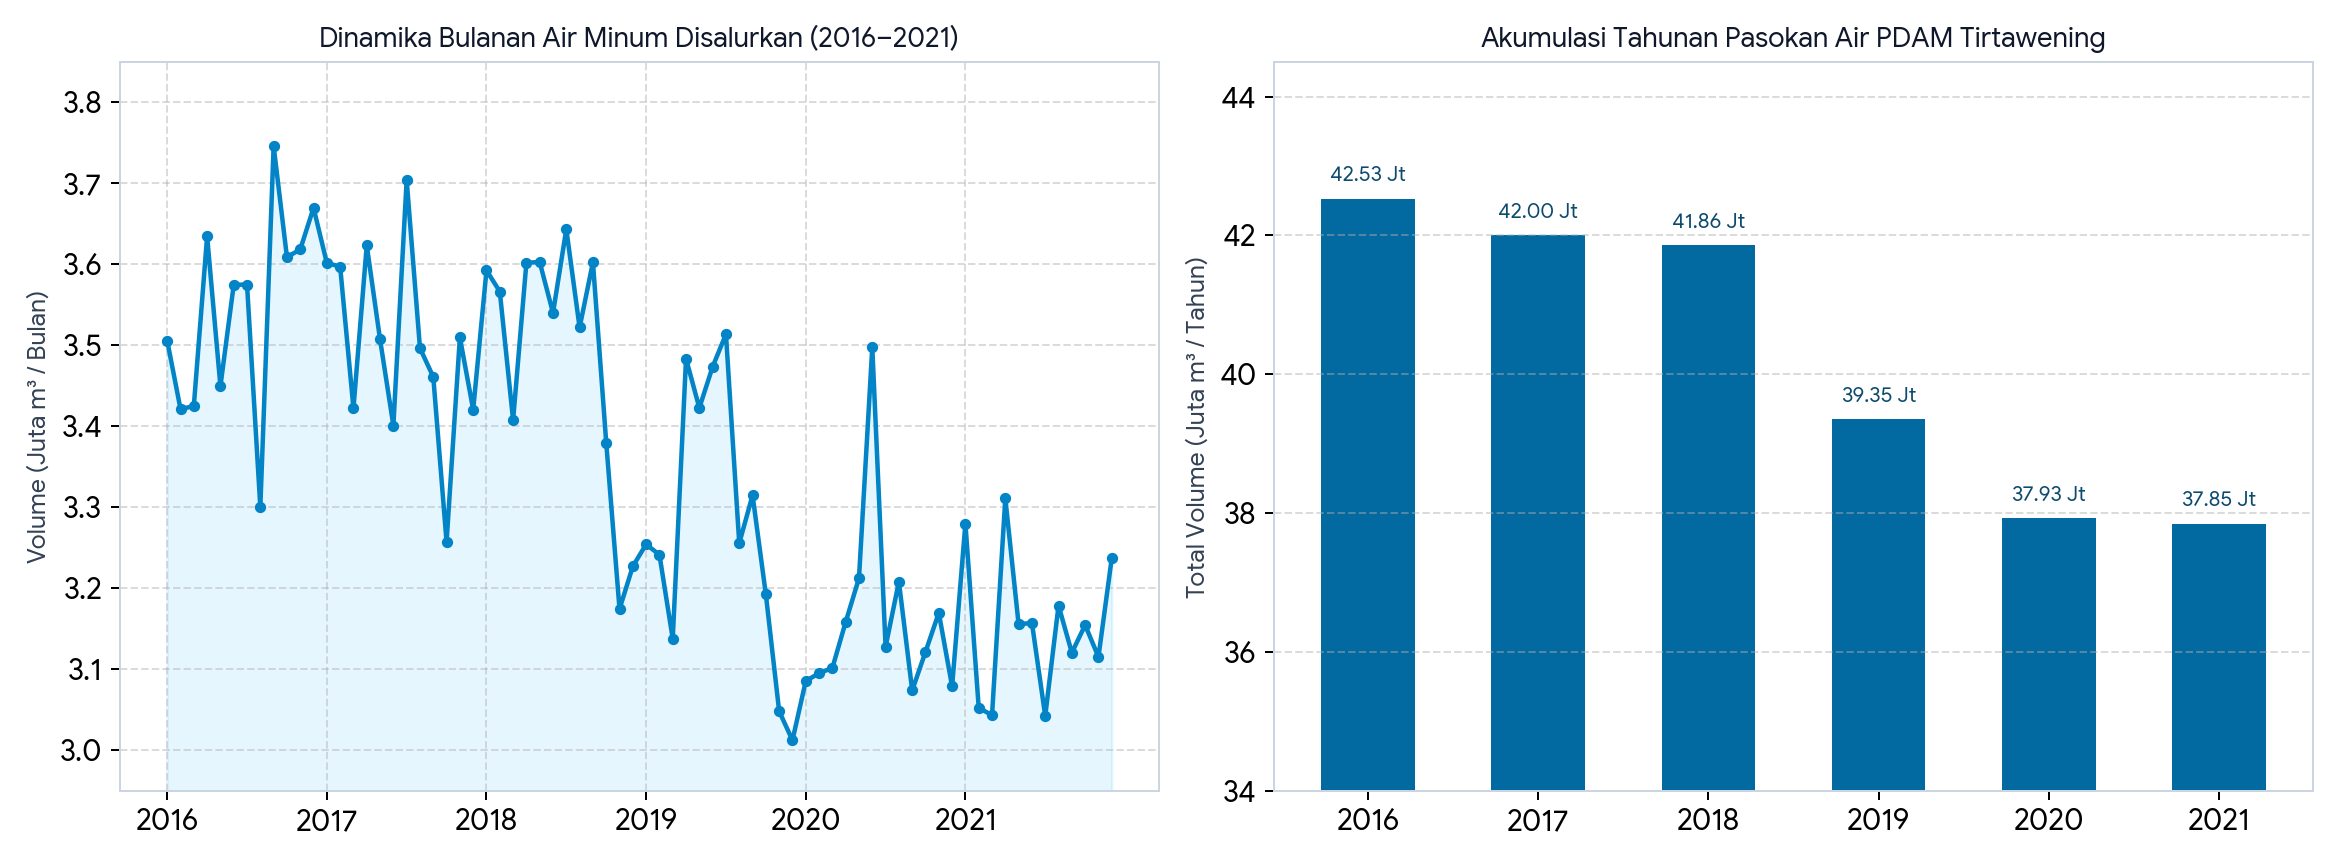

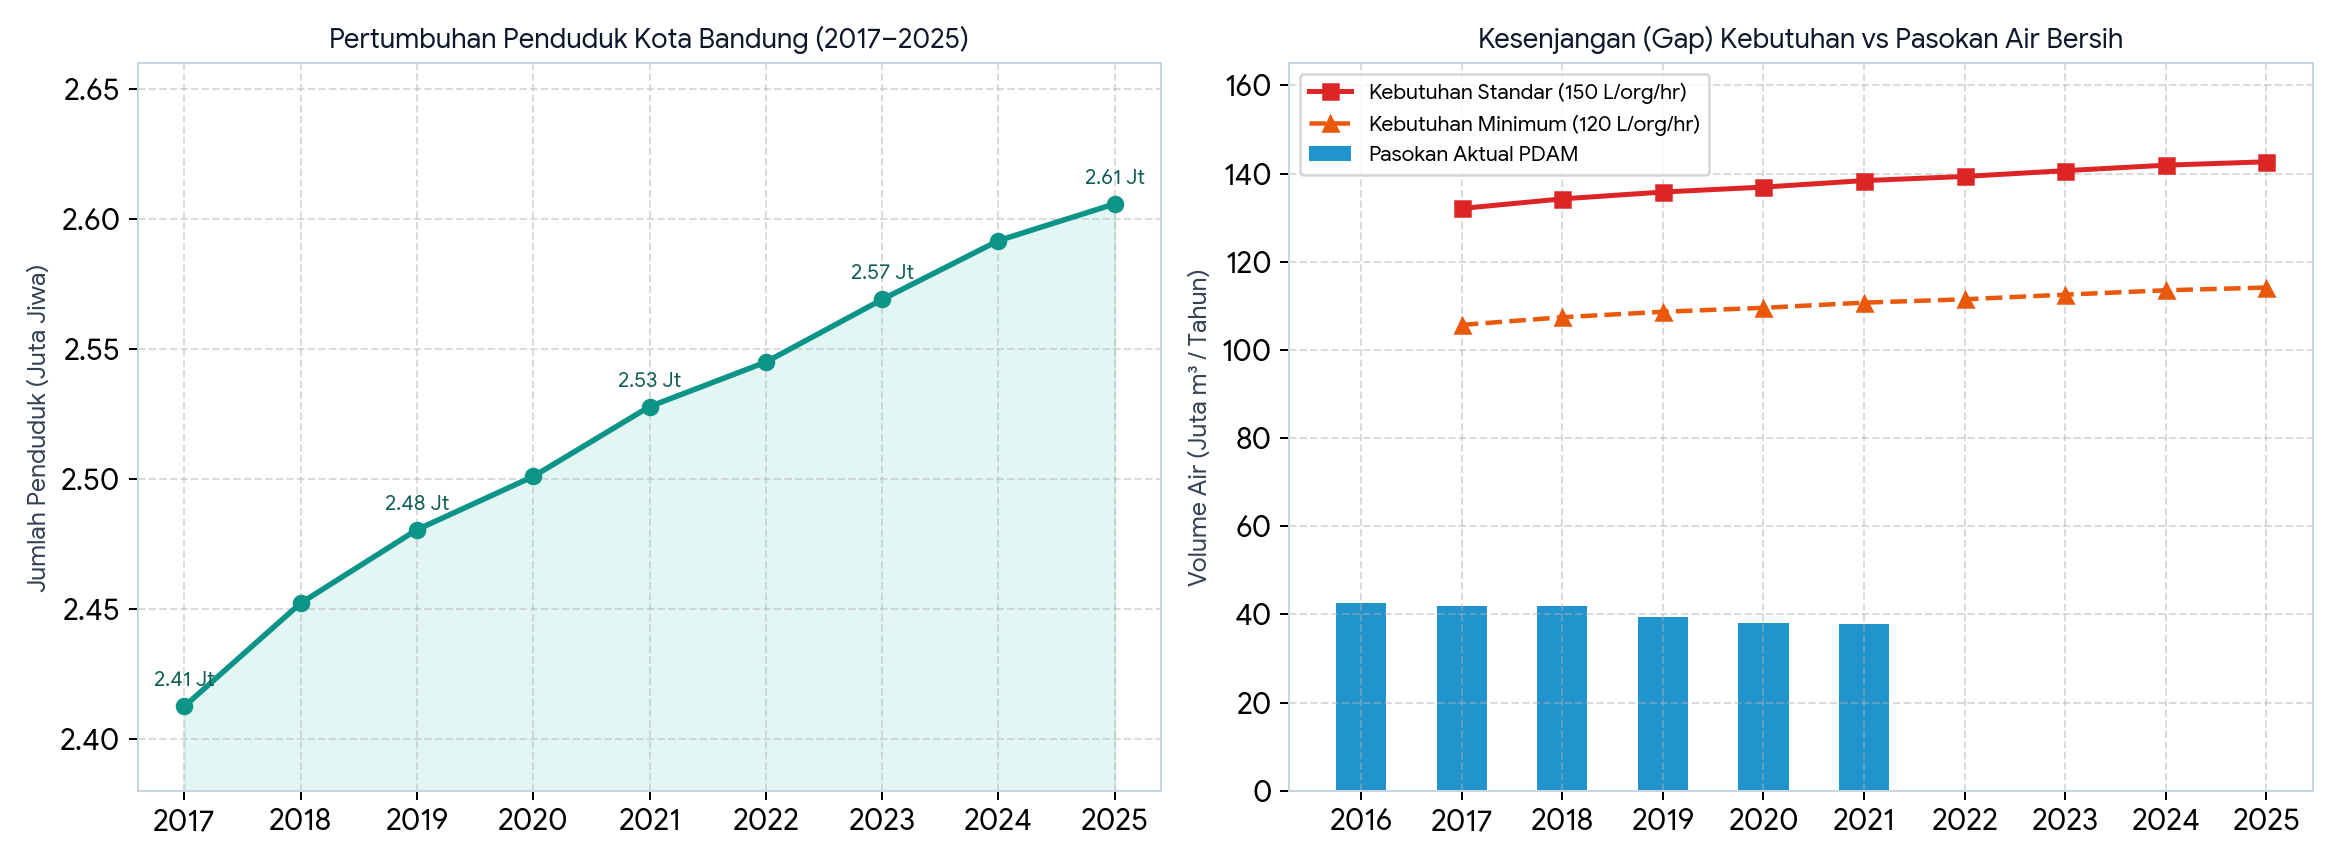

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
fig.patch.set_facecolor('white')
axes[0].plot(range(len(df_air)), df_air['jumlah_air_minum_disalurkan']/1e6, color='#0284c7', marker='o', markersize=3.5, linewidth=1.8)
axes[0].fill_between(range(len(df_air)), df_air['jumlah_air_minum_disalurkan']/1e6, 2.9, color='#38bdf8', alpha=0.12)
axes[0].set_title('Dinamika Bulanan Air Minum Disalurkan (2016–2021)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Volume (Juta m³ / Bulan)')
axes[0].set_xticks(range(0, 72, 12))
axes[0].set_xticklabels(['2016', '2017', '2018', '2019', '2020', '2021'])
axes[0].grid(True, linestyle='--', alpha=0.45)

bars = axes[1].bar(air_yearly['tahun'].astype(str), air_yearly['jumlah_air_minum_disalurkan']/1e6, color='#0369a1', width=0.55)
axes[1].set_title('Akumulasi Tahunan Pasokan Air PDAM Tirtawening', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Total Volume (Juta m³ / Tahun)')
axes[1].set_ylim(34, 44.5)
axes[1].grid(True, axis='y', linestyle='--', alpha=0.45)
plt.tight_layout()
plt.show()


### 2. Formulasi Matematis Model Sistem Dinamik (*Stock & Flow*)
Model disusun ke dalam **4 variabel *Stock* utama** dengan langkah integrasi $\Delta t = 0,25$ tahun:
1. **Populasi Penduduk $P(t)$** mengikuti kurva pertumbuhan logistik perkotaan dengan daya dukung $K_{\text{pop}} = 3.250.000$ jiwa:
   $$\frac{dP}{dt} = r_{\text{pop}} \cdot P(t) \cdot \left(1 - \frac{P(t)}{K_{\text{pop}}}\right)$$
2. **Kapasitas Produksi IPA Terpasang $C_{\text{ipa}}(t)$** ($\text{m}^3/\text{tahun}$):
   $$\frac{dC_{\text{ipa}}}{dt} = \alpha_{\text{spam}} \cdot C_{\text{ipa}}(t)$$
3. **Tingkat Kehilangan Air / *Non-Revenue Water* $\text{NRW}(t)$** (fraksi kebocoran teknis & komersial):
   $$\frac{d\text{NRW}}{dt} = \begin{cases} \beta_{\text{aus}} \cdot (\text{NRW}_{\max} - \text{NRW}(t)), & \text{tanpa intervensi} \\ -\gamma_{\text{rehab}} \cdot (\text{NRW}(t) - \text{NRW}_{\text{floor}}), & \text{dengan rehabilitasi DMA} \end{cases}$$
4. **Neraca Air & Akumulasi Defisit Perpipaan $D_{\text{cum}}(t)$**:
   $$Q_{\text{dist}}(t) = C_{\text{ipa}}(t) \cdot (1 - \text{NRW}(t)), \quad Q_{\text{demand}}(t) = P(t) \cdot q_{\text{kapita}} \cdot 365$$


MAPE Validasi Sub-Model Pasokan Air PDAM (2016–2021): 1.531%
MAPE Validasi Sub-Model Populasi Penduduk (2017–2025): 0.231%

Tabel Validasi Pasokan Air:
 tahun  jumlah_air_minum_disalurkan  pasokan_efektif  ape_pct
  2016                     42528447      42640250.00 0.262890
  2017                     42000663      41101563.40 2.140680
  2018                     41859962      39912964.62 4.651216
  2019                     39349569      38994800.36 0.901582
  2020                     37929761      38285540.33 0.937995
  2021                     37847379      37737653.83 0.289915


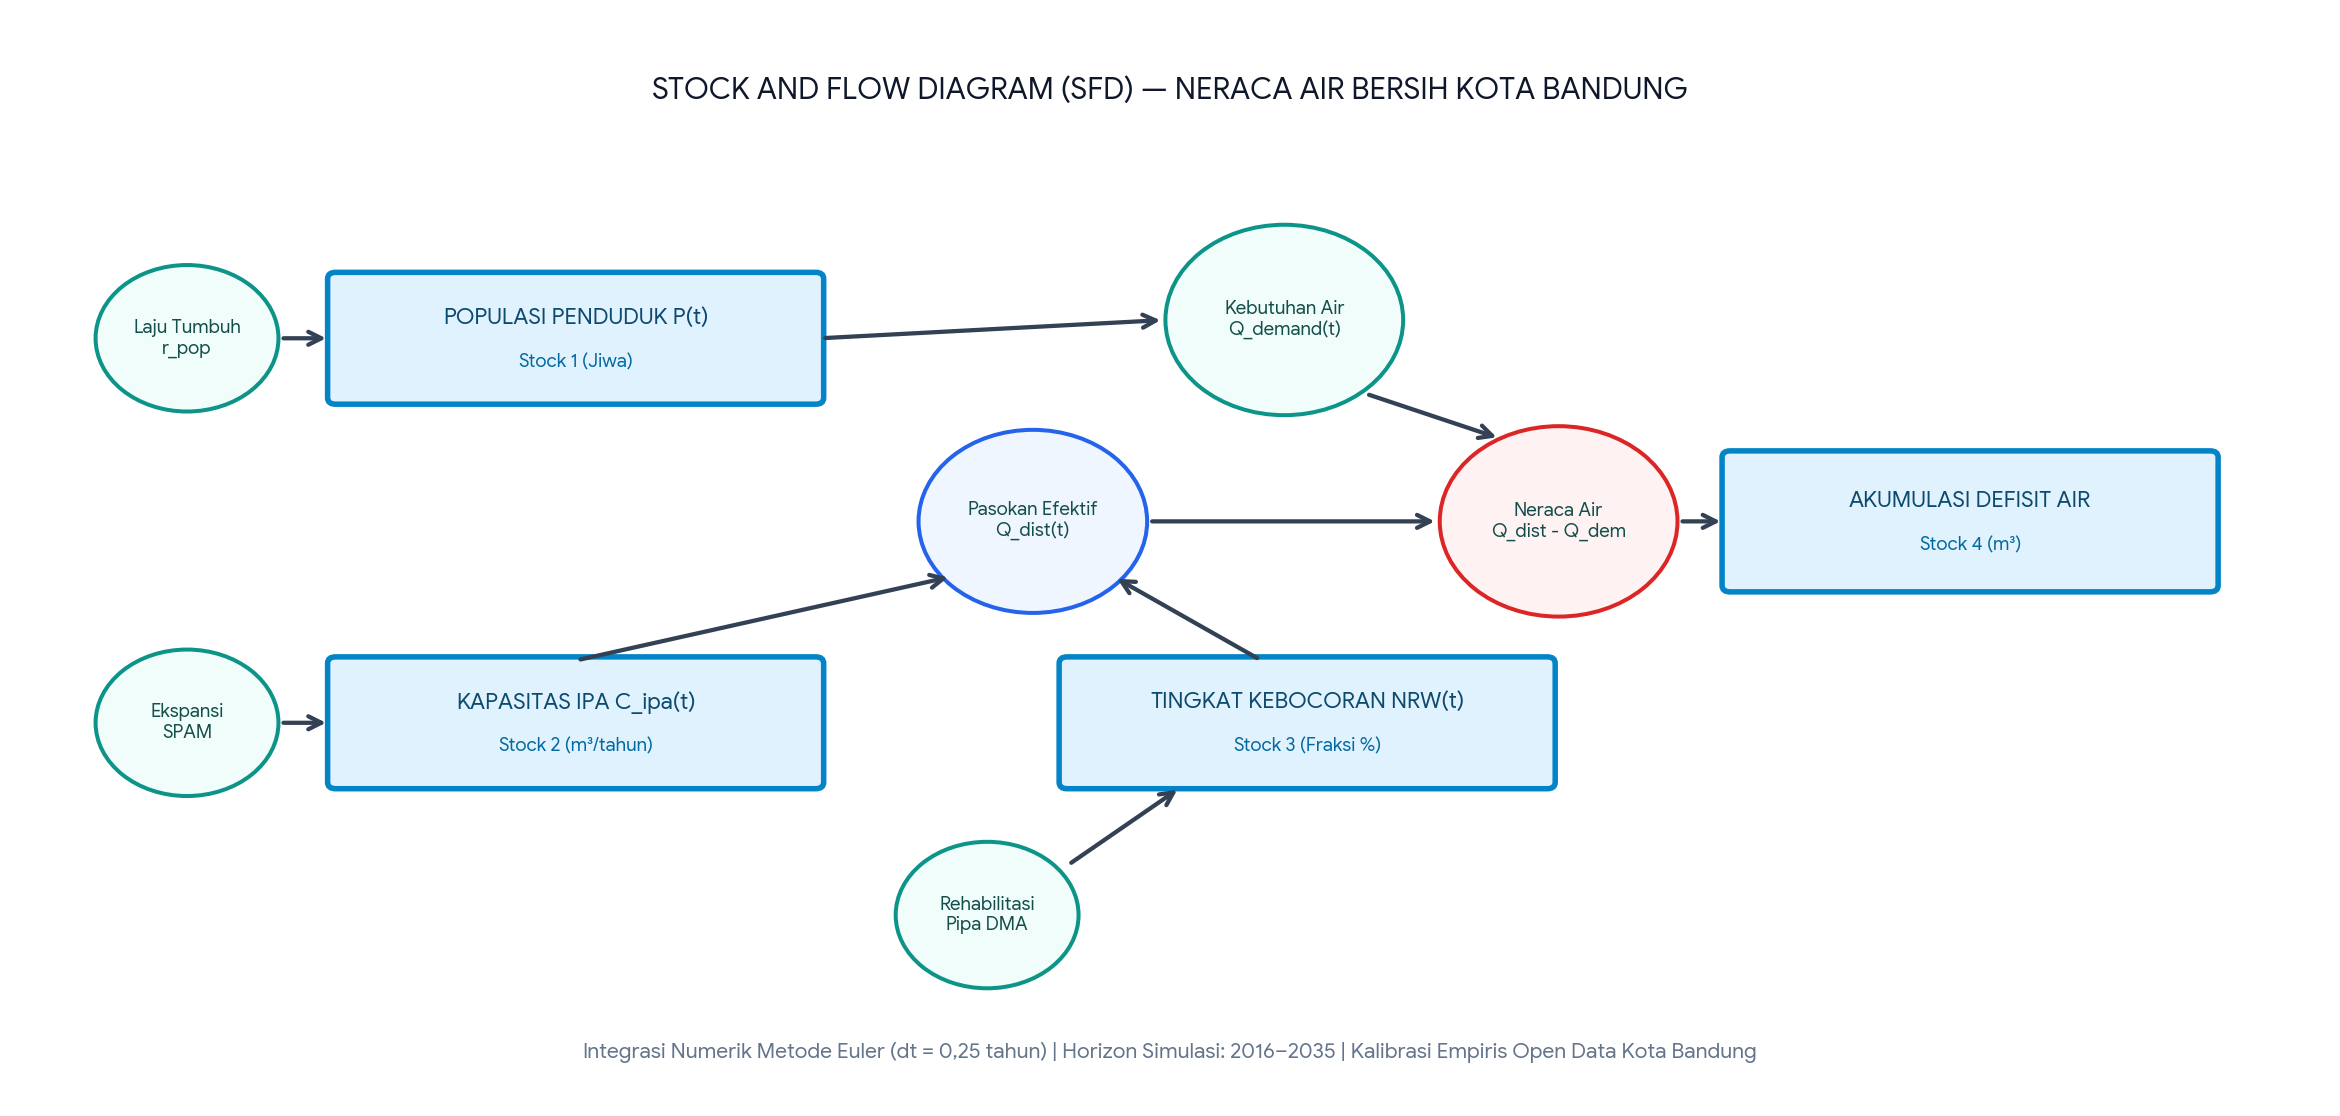

In [3]:
cagr_pop = (df_pop.loc[df_pop['tahun']==2025, 'jumlah_penduduk'].values[0] /
            df_pop.loc[df_pop['tahun']==2017, 'jumlah_penduduk'].values[0]) ** (1/8) - 1
p_2017 = df_pop.loc[df_pop['tahun']==2017, 'jumlah_penduduk'].values[0]
p_2016_est = p_2017 / (1 + cagr_pop)
K_pop = 3250000.0
r_pop = cagr_pop / (1 - (df_pop['jumlah_penduduk'].mean() / K_pop))

def run_sd_simulation(
    start_year=2016,
    end_year=2035,
    dt=0.25,
    nrw_target_reduction_rate=0.0,
    nrw_floor=0.18,
    ipa_expansion_rate=0.0,
    per_capita_demand_lpd=150.0,
    pop_growth_modifier=1.0
):
    steps = int((end_year - start_year) / dt) + 1
    times = np.linspace(start_year, end_year, steps)

    P = p_2016_est
    C_ipa = 63500000.0
    NRW = 0.3285
    Cum_Deficit = 0.0
    nrw_aging_rate = 0.25
    nrw_max_bau = 0.435

    records = []
    for t in times:
        q_dist = C_ipa * (1.0 - NRW)
        q_loss = C_ipa * NRW
        q_demand = P * (per_capita_demand_lpd / 1000.0) * 365.0
        neraca = q_dist - q_demand
        rasio_layanan = (q_dist / q_demand) * 100.0
        tekanan_air_tanah = max(0.0, -neraca)

        if abs(t - round(t)) < 1e-6:
            records.append({
                'tahun': int(round(t)),
                'populasi': round(P),
                'kapasitas_ipa': round(C_ipa, 2),
                'nrw_persen': round(NRW * 100.0, 2),
                'pasokan_efektif': round(q_dist, 2),
                'kehilangan_air': round(q_loss, 2),
                'kebutuhan_air': round(q_demand, 2),
                'neraca_air': round(neraca, 2),
                'rasio_layanan_pct': round(rasio_layanan, 2),
                'eksploitasi_air_tanah': round(tekanan_air_tanah, 2),
                'akumulasi_defisit': round(Cum_Deficit, 2)
            })

        dP_dt = (r_pop * pop_growth_modifier) * P * (1.0 - P / K_pop)
        policy_active = 1.0 if t >= 2022.0 else 0.0
        dC_dt = C_ipa * (ipa_expansion_rate * policy_active)

        if policy_active > 0 and nrw_target_reduction_rate > 0:
            dNRW_dt = -nrw_target_reduction_rate * (NRW - nrw_floor)
        else:
            dNRW_dt = nrw_aging_rate * (nrw_max_bau - NRW)

        dDef_dt = tekanan_air_tanah

        P = P + dP_dt * dt
        C_ipa = C_ipa + dC_dt * dt
        NRW = np.clip(NRW + dNRW_dt * dt, 0.10, 0.55)
        Cum_Deficit = Cum_Deficit + dDef_dt * dt

    return pd.DataFrame(records)

df_bau = run_sd_simulation(nrw_target_reduction_rate=0.0, nrw_floor=0.18, ipa_expansion_rate=0.0, per_capita_demand_lpd=150.0)
df_s1  = run_sd_simulation(nrw_target_reduction_rate=0.14, nrw_floor=0.18, ipa_expansion_rate=0.015, per_capita_demand_lpd=150.0)
df_s2  = run_sd_simulation(nrw_target_reduction_rate=0.18, nrw_floor=0.16, ipa_expansion_rate=0.048, per_capita_demand_lpd=135.0)

val_air = pd.merge(air_yearly, df_bau[['tahun', 'pasokan_efektif']], on='tahun')
val_air['ape_pct'] = np.abs((val_air['jumlah_air_minum_disalurkan'] - val_air['pasokan_efektif']) / val_air['jumlah_air_minum_disalurkan']) * 100

val_pop = pd.merge(df_pop[['tahun', 'jumlah_penduduk']], df_bau[['tahun', 'populasi']], on='tahun')
val_pop['ape_pct'] = np.abs((val_pop['jumlah_penduduk'] - val_pop['populasi']) / val_pop['jumlah_penduduk']) * 100

print(f"MAPE Validasi Sub-Model Pasokan Air PDAM (2016–2021): {val_air['ape_pct'].mean():.3f}%")
print(f"MAPE Validasi Sub-Model Populasi Penduduk (2017–2025): {val_pop['ape_pct'].mean():.3f}%")
print("\nTabel Validasi Pasokan Air:")
print(val_air.to_string(index=False))


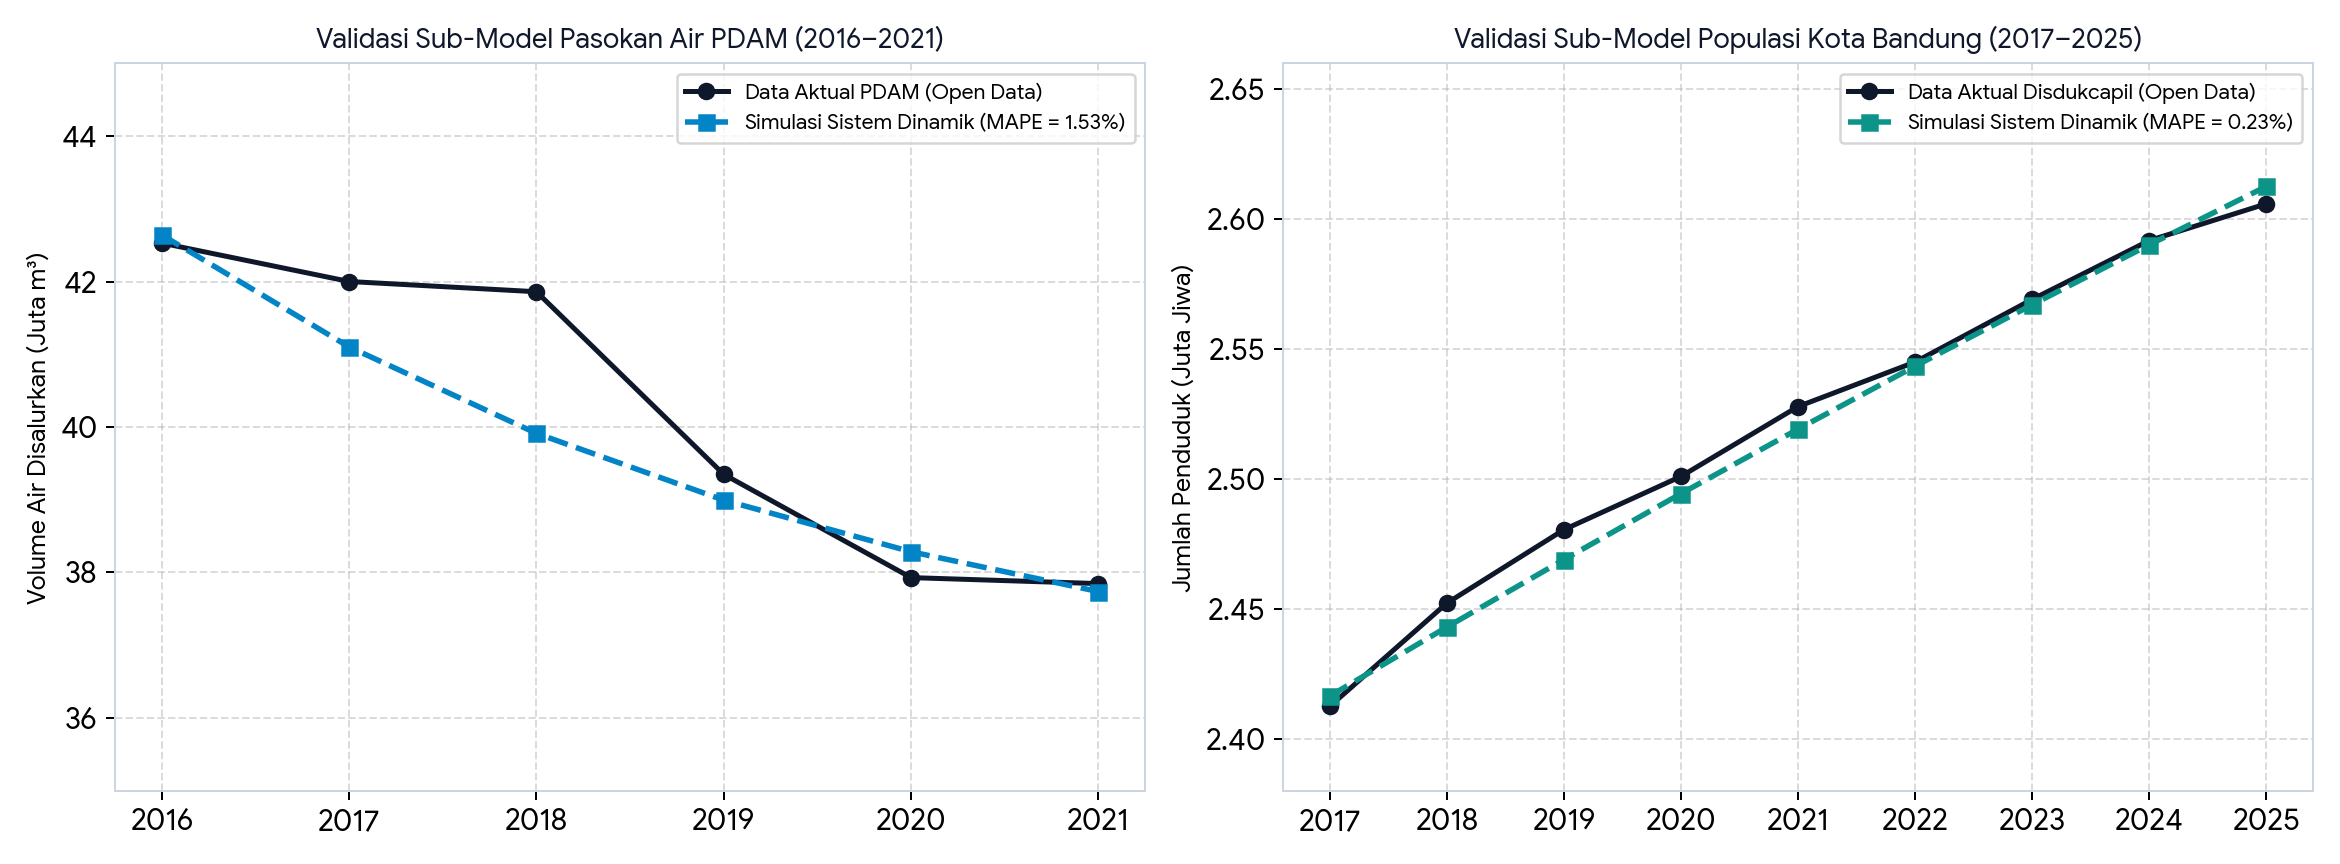

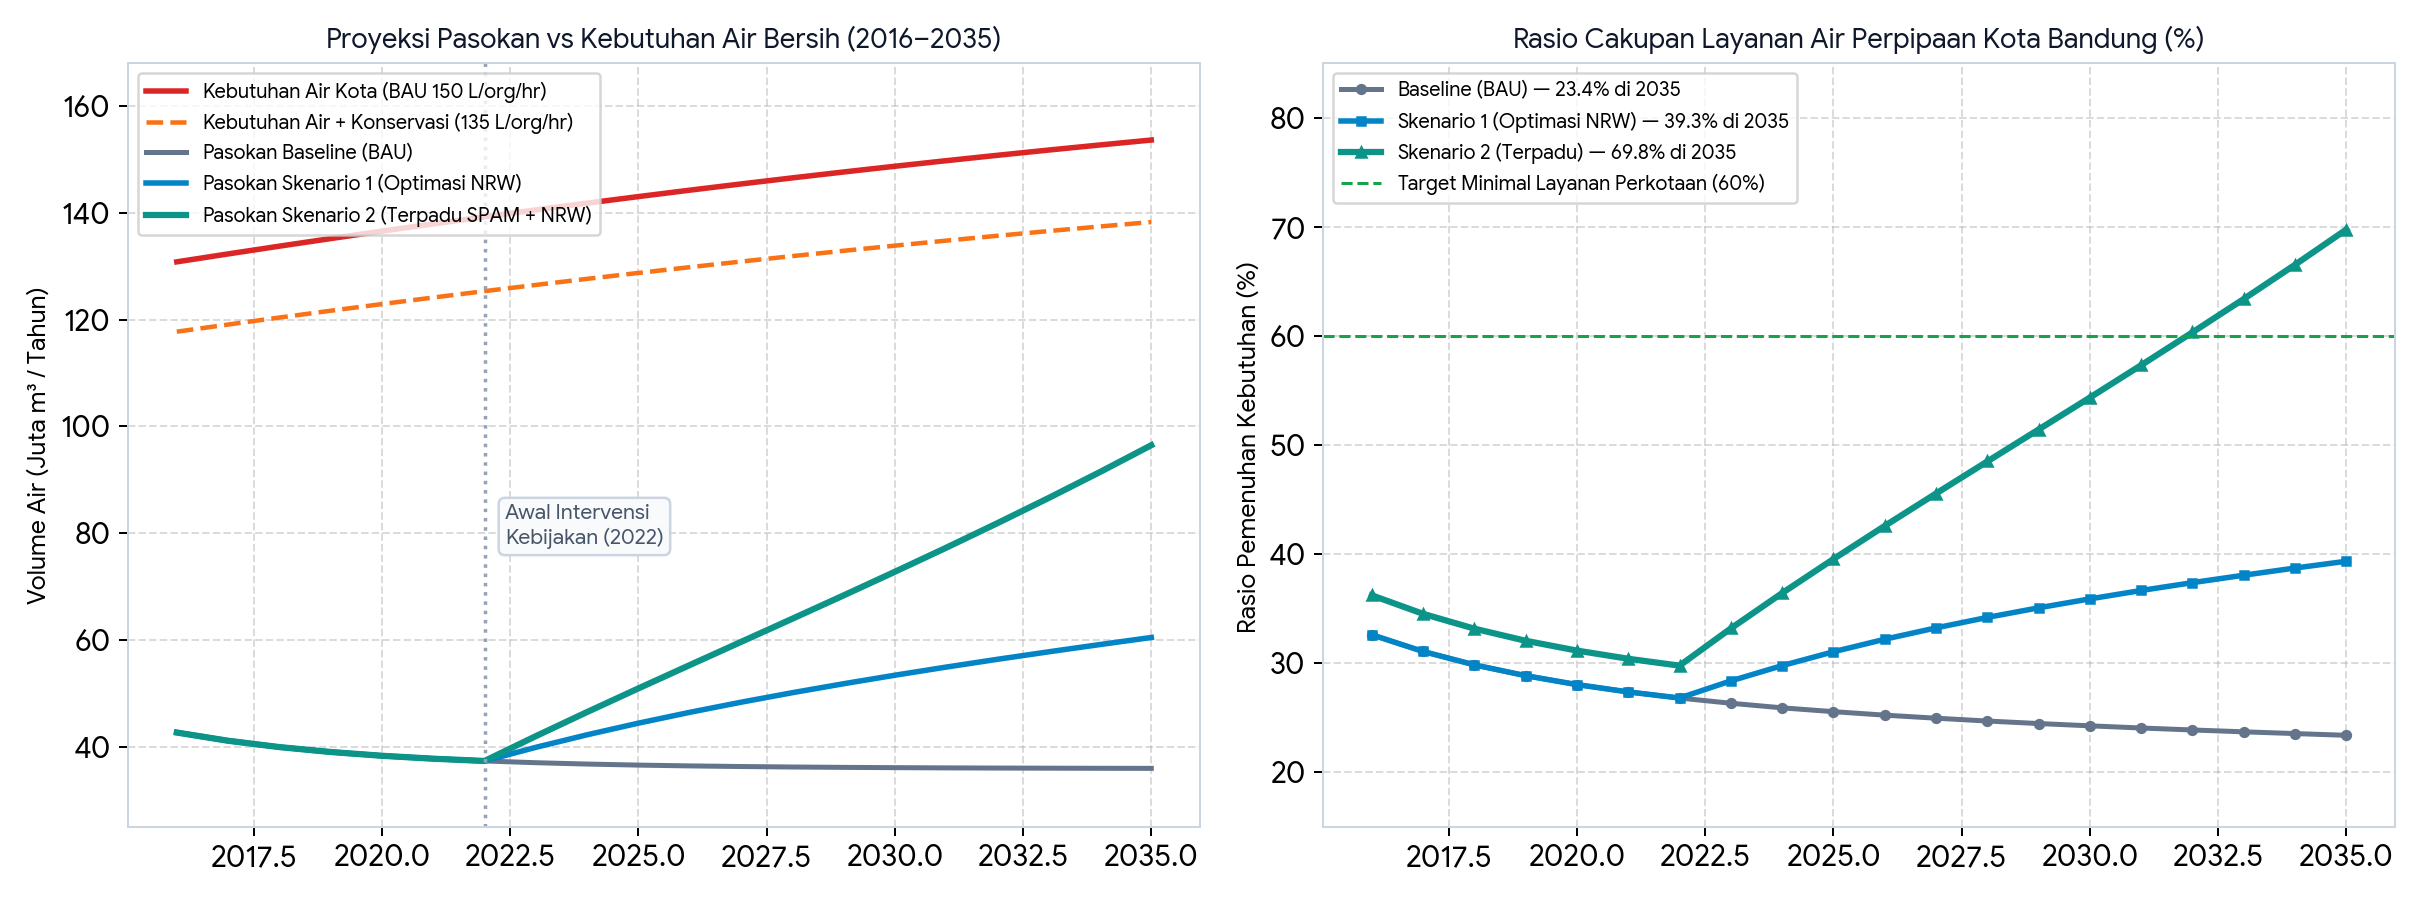

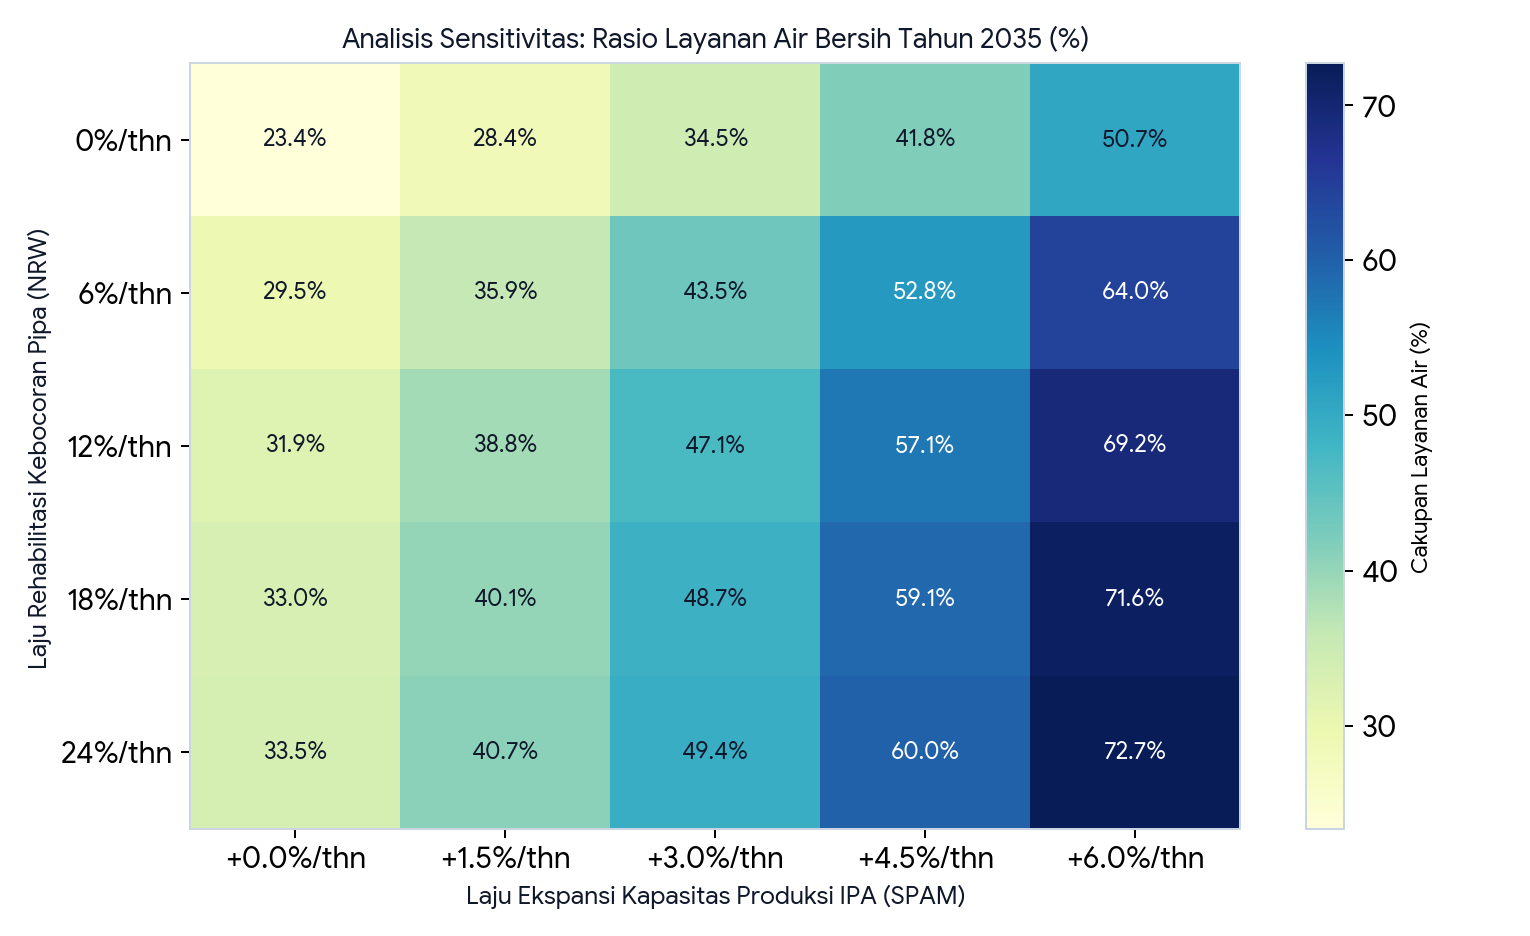

=== PERBANDINGAN PROYEKSI TAHUN 2035 ===
                       Skenario  populasi  nrw_persen  pasokan_efektif  kebutuhan_air  rasio_layanan_pct
   Baseline (Business as Usual) 2806125.0       43.42      35927611.84   153635342.72              23.38
      Skenario 1 (Optimasi NRW) 2806125.0       21.64      60446878.86   153635342.72              39.34
Skenario 2 (Terpadu SPAM + NRW) 2806125.0       18.30      96464763.32   138271808.45              69.76


In [4]:
# Visualisasi Hasil Validasi, Proyeksi Skenario 2016–2035 & Analisis Sensitivitas
plt.show()
print("=== PERBANDINGAN PROYEKSI TAHUN 2035 ===")
print(comp_2035.to_string(index=False))
